# Ordinary Least Squares Regression

The model for the line of best fit is: $y = mx + c$. This definition can be extented to become a model for the data by adding a parameter for i.i.d noise: $y = mx + c + \epsilon $

* $m$: Gradient of the line
* $c$: Intercept
* $\epsilon$: i.i.d noise

Mean value of x:

$\overline{x} = \frac{\Sigma x}{n}$

Mean value of y:

$\overline{y} = \frac{\Sigma y}{n}$

Gradient:

$m = \frac{S_{xy}}{S_{xx}} = \frac{\Sigma(x_i-\overline{x})(y_i-\overline{y})}{\Sigma(x_i-\overline{x})^2} = \frac{\Sigma(xy)-\frac{\Sigma x\Sigma y}{n}}{\Sigma(x^2)-\frac{(\Sigma x)^2}{n}}$

Intercept:

$c = \overline{y} - m\overline{x}$

## Setup

In [1]:
# Standard library imports
# n/a

# Third party imports
import matplotlib.pyplot as plt
import statsmodels.api as sm

## Data

In [2]:
xy = [
    [i, 200 + 100 * i + n]
    for i, n in zip(range(1, 11), [-7, 9, -15, 13, 5, 1, -13, 12, -5, 19])
]

(0.0, 1300.0)

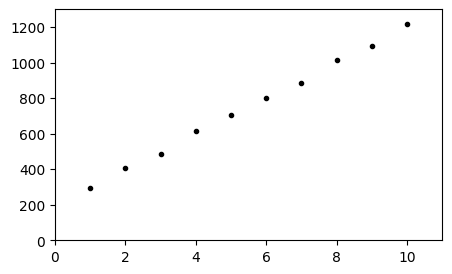

In [3]:
fig, _ = plt.subplots(nrows=1, ncols=1, figsize=(5, 3))

fig.axes[0].scatter(
    [x[0] for x in xy], [x[1] for x in xy],
    marker=".",
    color="black",
)

fig.axes[0].set_xlim((0, 11))
fig.axes[0].set_ylim((0, 1300))

## Method

In [4]:
def get_m(x: list, y: list, alternative: bool = False) -> float:
    """Get the gradient of the linear regression line of best fit.

    Args:
        x (list): Independent variable
        y (list): Dependent variable
        alternative (bool): Set to True to calculate with an alternative
            methodology. Defaults to False.

    Returns:
        float: Gradient of the line of best fit.
    """
    assert len(x) == len(y)

    n = len(x)

    x_mean = sum(x)/n
    y_mean = sum(y)/n

    if not alternative:
        sxy = sum([xi * yi for xi, yi in zip(x, y)]) - (sum(x) * sum(y))/n
        sxx = sum(xi**2 for xi in x) - ((sum(x))**2)/n

    else:
        sxy = sum([(xi - x_mean)*(yi - y_mean) for xi, yi in zip(x, y)])
        sxx = sum((xi - x_mean)**2 for xi in x)

    return sxy / sxx

In [5]:
def get_c(x: list, y: list, m: float) -> float:
    """Get the intercept of the linear regression line of best fit.

    Args:
        x (list): Independent variable
        y (list): Dependent variable

    Returns:
        float: Intercept of the line of best fit.
    """
    x_mean = sum(x)/n
    y_mean = sum(y)/n

    return y_mean - m * x_mean

In [6]:
n = len(xy)
x = [x[0] for x in xy]
y = [x[1] for x in xy]

In [7]:
m = get_m(x=x, y=y)

In [8]:
c = get_c(x=x, y=y, m=m)

Visualize Results

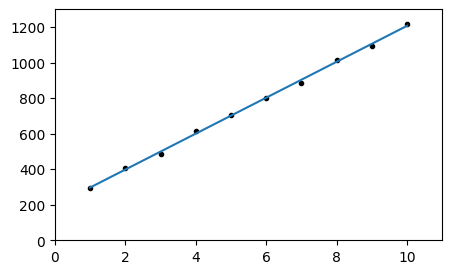

In [9]:
fig.axes[0].plot(x, [m * xi + c for xi in x])
fig

## Checks

In [10]:
assert round(get_m(x=x, y=y, alternative=False), 12) == round(get_m(x=x, y=y, alternative=True), 12)

Check the model ties up with the commonly used open source approach

In [11]:
# Note: Need to use `sm.add_constant` to add y-intercept
mod = sm.OLS(y, sm.add_constant(x))

results = mod.fit()

In [12]:
assert round(results.params[0], 12) == round(get_c(x=x, y=y, m=m), 12)

In [13]:
assert round(results.params[1], 12) == round(get_m(x=x, y=y, alternative=False), 12)